# **Run 6: Frozen ViT-L/16 (SWAG) features + linear classifier (target: 99%+)**
Run 5 fully fine-tuned a pretrained ViT-B/16 and reached 97.80% (`assignment_2_vit_run5.ipynb`). It overfit (99.8% train
accuracy) and the high learning rate early on damaged the pretrained features (78.8% test accuracy after epoch 1).

This run does the opposite: the pretrained network is **frozen** and only a linear classifier is trained on its features.
- **Backbone:** torchvision ViT-L/16 with SWAG weights (304M params, weakly-supervised pretraining on 3.6B Instagram images,
  Meta AI). The `SWAG_LINEAR` weights are the version intended for frozen-feature use. Its features are strong enough that a
  linear layer separates the CIFAR-10 classes very well, and with nothing to fine-tune the backbone can't overfit or forget.
- **Features:** each image is upscaled 32 -> 224 px and passed through the backbone once. The feature vector is the CLS token
  concatenated with the average of the patch tokens (1024 + 1024 = 2048 dims).
- **Augmentation:** the horizontally flipped copy of every training image is added as an extra training example, and test
  predictions average the image and its flip (flip TTA).
- **Classifier:** a single `nn.Linear(2048, 10)` trained on the cached features. That takes seconds instead of hours.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

c:\Users\Admin\Documents\GitHub\DL-Assignment2-CNN-CIFAR\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda NVIDIA GeForce RTX 4080 SUPER


# **Data**

In [2]:
IMG_SIZE = 224                                          # 14x14 patches of 16 px
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# no random augmentation: every image goes through the frozen backbone exactly once (plus its flip)
train_dataset = datasets.CIFAR10(root="../dataset", train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.CIFAR10(root="../dataset", train=False, download=True, transform=transforms.ToTensor())

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)
classes = train_dataset.classes

def to_model_input(images):
    """32x32 [0,1] batch on GPU -> 224x224 ImageNet-normalized batch"""
    images = F.interpolate(images, size=IMG_SIZE, mode="bicubic", align_corners=False).clamp(0, 1)
    return (images - IMAGENET_MEAN) / IMAGENET_STD

print(f"Train length: {len(train_dataset)}\nTest length: {len(test_dataset)}\nClasses: {classes}")

Train length: 50000
Test length: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Backbone: pretrained ViT-L/16 SWAG (frozen)**

In [3]:
from torchvision.models import vit_l_16, ViT_L_16_Weights

backbone = vit_l_16(weights=ViT_L_16_Weights.IMAGENET1K_SWAG_LINEAR_V1).to(device).eval()   # downloads ~1.2GB once
for p in backbone.parameters():
    p.requires_grad = False
print(f"Backbone parameters: {sum(p.numel() for p in backbone.parameters()) / 1e6:.0f}M (all frozen)")

Backbone parameters: 304M (all frozen)


# **Extract features once**

In [4]:
@torch.no_grad()
def extract_features(images):
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        x = backbone._process_input(to_model_input(images))         # patch embedding: (N, 196, 1024)
        cls = backbone.class_token.expand(x.shape[0], -1, -1)
        tokens = backbone.encoder(torch.cat([cls, x], dim=1))       # transformer + final LayerNorm: (N, 197, 1024)
    cls_token = tokens[:, 0]                                        # (N, 1024)
    patch_mean = tokens[:, 1:].mean(dim=1)                          # (N, 1024)
    return torch.cat([cls_token, patch_mean], dim=1).float()        # (N, 2048)

@torch.no_grad()
def extract_dataset(loader):
    feats, feats_flip, labels = [], [], []
    for images, y in tqdm(loader, desc="Extracting", leave=False):
        images = images.to(device, non_blocking=True)
        feats.append(extract_features(images))
        feats_flip.append(extract_features(torch.flip(images, dims=[3])))
        labels.append(y.to(device))
    return torch.cat(feats), torch.cat(feats_flip), torch.cat(labels)

train_feats, train_feats_flip, train_labels = extract_dataset(train_loader)
test_feats, test_feats_flip, test_labels = extract_dataset(test_loader)

# flipped training images are extra examples; standardize with training statistics
X_train = torch.cat([train_feats, train_feats_flip])
y_train = torch.cat([train_labels, train_labels])
feat_mean, feat_std = X_train.mean(0), X_train.std(0) + 1e-6
X_train = (X_train - feat_mean) / feat_std
X_test = (test_feats - feat_mean) / feat_std
X_test_flip = (test_feats_flip - feat_mean) / feat_std
print(f"Train features: {tuple(X_train.shape)}, test features: {tuple(X_test.shape)}")

Train features: (100000, 2048), test features: (10000, 2048)


# **Train the linear classifier**

Epoch 1/30 | train loss 1.3971 | train acc 0.6919 | test loss 0.7810 | test acc 0.9424
Epoch 2/30 | train loss 0.6787 | train acc 0.9597 | test loss 0.6382 | test acc 0.9681
Epoch 3/30 | train loss 0.6176 | train acc 0.9727 | test loss 0.6078 | test acc 0.9743
Epoch 4/30 | train loss 0.5938 | train acc 0.9774 | test loss 0.5912 | test acc 0.9764
Epoch 5/30 | train loss 0.5800 | train acc 0.9803 | test loss 0.5823 | test acc 0.9778
Epoch 6/30 | train loss 0.5712 | train acc 0.9822 | test loss 0.5772 | test acc 0.9789
Epoch 7/30 | train loss 0.5652 | train acc 0.9841 | test loss 0.5741 | test acc 0.9792
Epoch 8/30 | train loss 0.5608 | train acc 0.9854 | test loss 0.5722 | test acc 0.9793
Epoch 9/30 | train loss 0.5576 | train acc 0.9867 | test loss 0.5714 | test acc 0.9797
Epoch 10/30 | train loss 0.5551 | train acc 0.9875 | test loss 0.5703 | test acc 0.9792
Epoch 11/30 | train loss 0.5531 | train acc 0.9883 | test loss 0.5695 | test acc 0.9797
Epoch 12/30 | train loss 0.5516 | train a

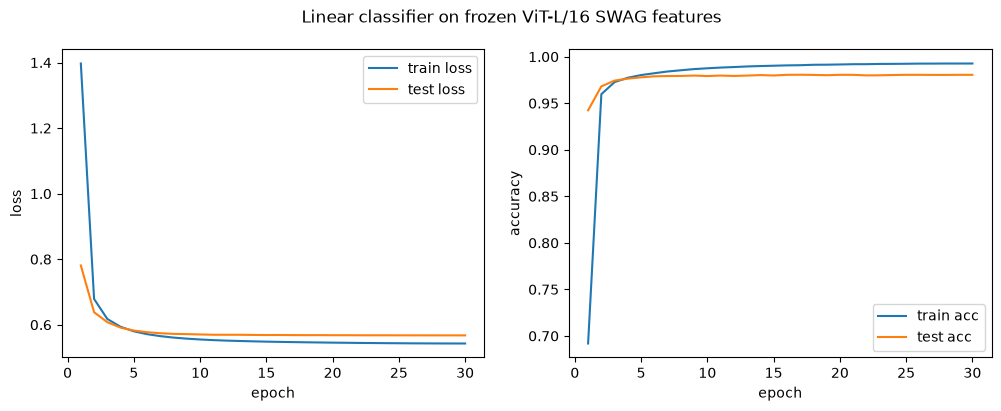

In [5]:
EPOCHS = 30
BATCH_SIZE = 1024

classifier = nn.Linear(X_train.shape[1], 10).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(classifier.parameters(), lr=1e-3, weight_decay=1e-2)
steps_per_epoch = (len(X_train) + BATCH_SIZE - 1) // BATCH_SIZE
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=1e-3, epochs=EPOCHS, steps_per_epoch=steps_per_epoch)

def evaluate(tta=True):
    classifier.eval()
    with torch.no_grad():
        logits = classifier(X_test)
        if tta:                                         # average with the flipped image's prediction
            logits = (logits + classifier(X_test_flip)) / 2
        loss = criterion(logits, test_labels).item()
        acc = (logits.argmax(1) == test_labels).float().mean().item()
    return loss, acc, logits.argmax(1)

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
for epoch in range(EPOCHS):
    classifier.train()
    perm = torch.randperm(len(X_train), device=device)
    total_loss, correct = 0, 0
    for i in range(0, len(X_train), BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE]
        outputs = classifier(X_train[idx])
        loss = criterion(outputs, y_train[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(idx)
        correct += (outputs.argmax(1) == y_train[idx]).sum().item()
    te_loss, te_acc, _ = evaluate()
    history["train_loss"].append(total_loss / len(X_train)); history["train_acc"].append(correct / len(X_train))
    history["test_loss"].append(te_loss); history["test_acc"].append(te_acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {history['train_loss'][-1]:.4f} | "
          f"train acc {history['train_acc'][-1]:.4f} | test loss {te_loss:.4f} | test acc {te_acc:.4f}")

epochs = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, history["train_loss"], label="train loss"); ax1.plot(epochs, history["test_loss"], label="test loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()
ax2.plot(epochs, history["train_acc"], label="train acc"); ax2.plot(epochs, history["test_acc"], label="test acc")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
fig.suptitle("Linear classifier on frozen ViT-L/16 SWAG features")
plt.show()
torch.save({"classifier": classifier.state_dict(), "feat_mean": feat_mean, "feat_std": feat_std},
           "vitl16_linear_cifar10.pth")

# **Final Results**

In [6]:
_, acc_plain, _ = evaluate(tta=False)
_, acc_tta, preds = evaluate(tta=True)
print(f"Test accuracy without TTA: {acc_plain:.4f}")
print(f"Test accuracy with flip TTA: {acc_tta:.4f}")

# per-class accuracy
for c, name in enumerate(classes):
    mask = test_labels == c
    print(f"{name:>10}: {(preds[mask] == c).float().mean().item():.4f}")

Test accuracy without TTA: 0.9803
Test accuracy with flip TTA: 0.9805
  airplane: 0.9800
automobile: 0.9930
      bird: 0.9710
       cat: 0.9580
      deer: 0.9850
       dog: 0.9680
      frog: 0.9860
     horse: 0.9920
      ship: 0.9850
     truck: 0.9870
